# Notebook 07 - diagnosis: what physically changed in 2026?
Notebook 05 showed that even when the model knows how fast every car is, 2026 laps stay harder to predict: the rules changed *how a race unfolds*, not just the pecking order. This notebook goes after the physics. Reads `data/model_table.csv.gz`, `results/model_config.json` and the qualifying laps.

1. SHAP: which features the model leans on before vs after seeing 2026
2. Where on the lap the 2026 cars lost time: sectors and speed traps
3. What removing DRS did to the car behind
4. Saturday vs Sunday: the gap between qualifying and race pace
5. Separating fuel burn from tyre wear, era by era
6. Summary: what changed

In [1]:
import os, sys
# Run from the repo root so data/, figures/ and results/ resolve, and make src/ importable.
if os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('..')
sys.path.insert(0, os.path.abspath('src'))

import json
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import xgboost as xgb
from f1lap.features import encode_features
from f1lap.clean import load_quali
from f1lap.features import quali_features
from f1lap.models import SEED, CONFIG_PATH, make_xgb

np.random.seed(SEED)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
cfg = json.load(open(CONFIG_PATH))   # final feature set + tuned params, chosen in notebook 04
df = pd.read_csv('data/model_table.csv.gz')
X_all = encode_features(df, cfg['groups'], cfg['team'])   # one aligned matrix, sliced per split
y_all = df['lap_delta_s']
FEATURE_COLS = list(X_all.columns)
XGB_PARAMS = cfg['xgb_params']
print('Feature set:', cfg['name'], '|', X_all.shape[1], 'features | params:', XGB_PARAMS)
SEASONS = [2022, 2023, 2024, 2025, 2026]
pd.set_option('future.no_silent_downcasting', True)

Feature set: + weather (all) | 39 features | params: {'learning_rate': 0.01, 'max_depth': 5, 'min_child_weight': 400, 'n_estimators': 1000}


### 1. SHAP before vs after seeing 2026
SHAP values come straight from **XGBoost's native `pred_contribs`**, which is the same TreeSHAP algorithm the `shap` library wraps, so there's no extra dependency.

In [2]:
m_pre = make_xgb(**XGB_PARAMS).fit(X_all[df.season < 2026], y_all[df.season < 2026].values)
m_post = make_xgb(**XGB_PARAMS).fit(X_all, y_all.values)
dm = xgb.DMatrix(X_all[df.season == 2026])
def mean_abs_shap(m):
    c = m.get_booster().predict(dm, pred_contribs=True)[:, :-1]   # drop the bias column
    return pd.Series(np.abs(c).mean(0), index=FEATURE_COLS)
shap_cmp = pd.DataFrame({'2022-2025': mean_abs_shap(m_pre), 'incl_2026': mean_abs_shap(m_post)})
shap_cmp['change'] = shap_cmp['incl_2026'] - shap_cmp['2022-2025']
top = shap_cmp.sort_values('incl_2026', ascending=False).head(12)
print('Mean |SHAP| on 2026 laps (top 12 features):')
top.round(4)

Mean |SHAP| on 2026 laps (top 12 features):


,2022-2025,incl_2026,change
fuel_proxy,0.6063,0.5844,-0.0219
recent_pace,0.4848,0.5468,0.0620
position,0.1514,0.1699,0.0185
stint,0.1143,0.1124,-0.0019
lap_length_m,0.1200,0.0973,-0.0227
stint_lap,0.1084,0.0960,-0.0124
team_quali_gap_pct,0.0514,0.0876,0.0362
gap_behind_s,0.0942,0.0844,-0.0098
quali_rank,0.0671,0.0725,0.0054
gap_ahead_s,0.0673,0.0653,-0.0020


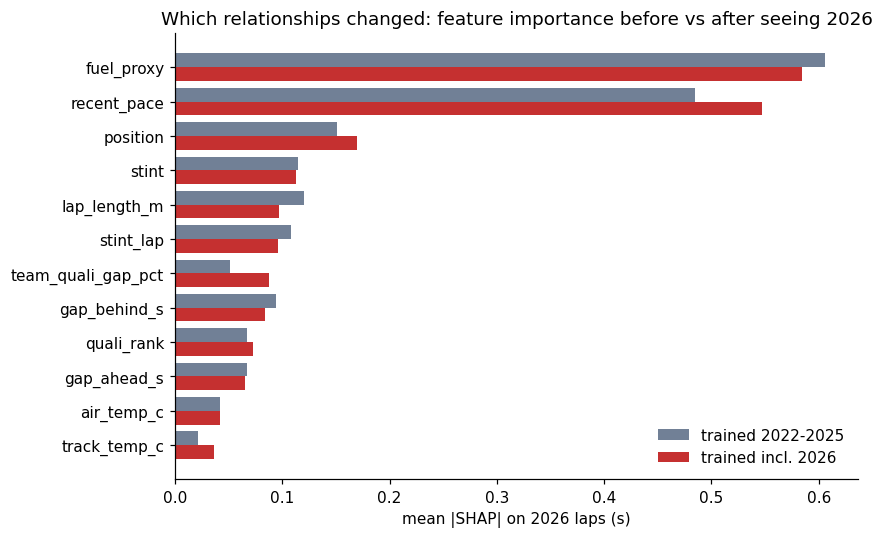

In [3]:
t = top.sort_values('incl_2026')
yy = np.arange(len(t)); h = 0.4
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(yy + h / 2, t['2022-2025'], height=h, label='trained 2022-2025', color='#718096')
ax.barh(yy - h / 2, t['incl_2026'], height=h, label='trained incl. 2026', color='#c53030')
ax.set_yticks(yy); ax.set_yticklabels(t.index); ax.set_xlabel('mean |SHAP| on 2026 laps (s)')
ax.set_title('Which relationships changed: feature importance before vs after seeing 2026')
ax.legend(frameon=False)
plt.tight_layout(); plt.savefig('figures/08_shap_comparison.png', dpi=150); plt.show()

**Figure 08.** The model now leans on **measured pace**. On 2026 laps the biggest attributions are `fuel_proxy` (laps of fuel on board) and `recent_pace` (how fast the driver has been over the last few laps), and once 2026 is in training the two features that gain the most are `recent_pace` (+0.06 s) and `team_quali_gap_pct` (+0.04 s, nearly doubling), both measurements re-taken every weekend. `position`, which dominated our first iteration, now carries a third of the attribution it used to (0.15 vs 0.47 s): it was mostly a stand-in for car pace, and the measurement features now carry that signal directly. Note that the "incl. 2026" model is explained on laps it was trained on, so this is an attribution comparison, not a test score.

### 2. Where on the lap did the 2026 cars lose time?
For every circuit raced dry in both 2025 and 2026 we compare the median clean lap, each of the three sectors, and the four speed traps (first and second intermediate, finish line, and the main speed trap). The 2026 rules cut downforce and changed the power unit to a ~50/50 combustion/electric split, so we'd expect two signatures: slower corners (less grip) and, on long straights, lower top speeds where the battery runs out ("clipping").

14 circuits | median lap-time change +2.23%
corr(lap-time change, longest straight) = -0.23 | corr(lap-time change, share of lap that is straight) = -0.19
median speed change (kph): {'speed_i1_kph': -6.0, 'speed_i2_kph': -4.0, 'speed_fl_kph': 8.0, 'speed_trap_kph': 1.0}


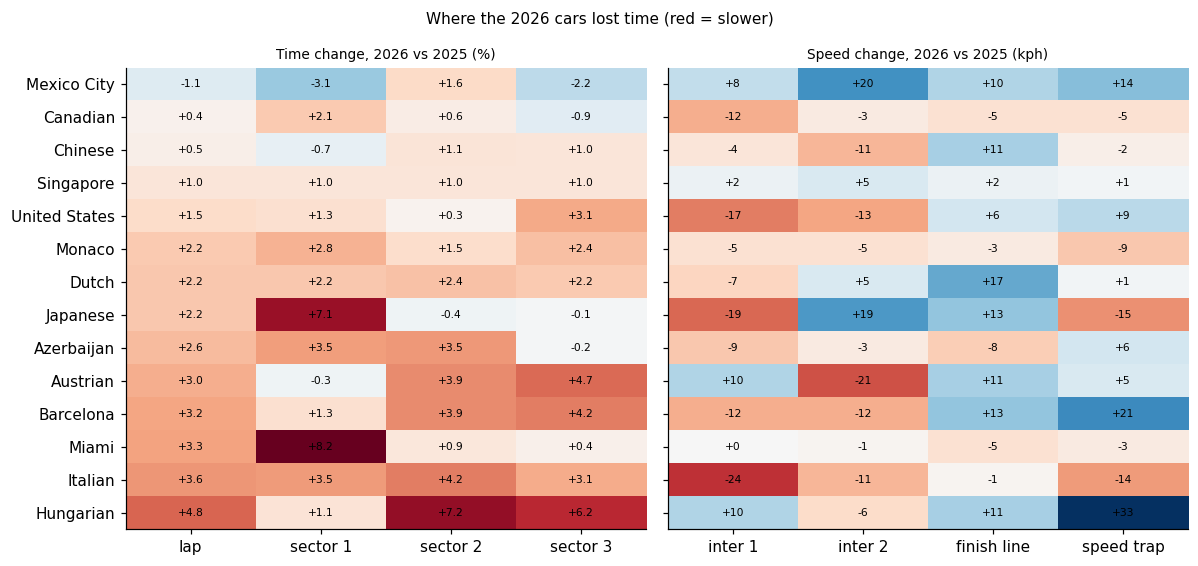

In [4]:
pair = df[df.season.isin([2025, 2026])]
sect = ['lap_time_s', 'sector1_s', 'sector2_s', 'sector3_s']
traps = ['speed_i1_kph', 'speed_i2_kph', 'speed_fl_kph', 'speed_trap_kph']
med = pair.groupby(['circuit', 'season'])[sect + traps].median().unstack('season').dropna()
pct = pd.DataFrame({c: (med[(c, 2026)] / med[(c, 2025)] - 1) * 100 for c in sect})
kph = pd.DataFrame({c: med[(c, 2026)] - med[(c, 2025)] for c in traps})
pct = pct.sort_values('lap_time_s'); kph = kph.loc[pct.index]
straight = df.groupby('circuit')[['longest_straight_m', 'frac_straight']].first().loc[pct.index]
print(f'{len(pct)} circuits | median lap-time change {pct.lap_time_s.median():+.2f}%')
print('corr(lap-time change, longest straight) = %.2f | corr(lap-time change, share of lap that is straight) = %.2f'
      % (pct.lap_time_s.corr(straight.longest_straight_m), pct.lap_time_s.corr(straight.frac_straight)))
print('median speed change (kph):', kph.median().round(1).to_dict())

fig, axs = plt.subplots(1, 2, figsize=(11, 5.2), gridspec_kw={'width_ratios': [4, 4]})
for ax, data, title, unit in [(axs[0], pct, 'Time change, 2026 vs 2025 (%)', '%'), (axs[1], kph, 'Speed change, 2026 vs 2025 (kph)', '')]:
    lim = np.nanmax(np.abs(data.values))
    im = ax.imshow(data.values, cmap='RdBu_r' if unit else 'RdBu', vmin=-lim, vmax=lim, aspect='auto')
    for (r, c), v in np.ndenumerate(data.values):
        ax.text(c, r, f'{v:+.1f}' if unit else f'{v:+.0f}', ha='center', va='center', fontsize=7)
    ax.set_xticks(range(data.shape[1])); ax.set_yticks(range(data.shape[0])); ax.set_yticklabels(data.index)
    ax.set_title(title, fontsize=9)
axs[0].set_xticklabels(['lap', 'sector 1', 'sector 2', 'sector 3'])
axs[1].set_xticklabels(['inter 1', 'inter 2', 'finish line', 'speed trap']); axs[1].set_yticklabels([])
fig.suptitle('Where the 2026 cars lost time (red = slower)', fontsize=10)
plt.tight_layout(); plt.savefig('figures/15_where_2026_slower.png', dpi=150); plt.show()

**Figure 15.** The simple "they're slow on the straights" story doesn't hold. Top speeds barely moved at the median circuit, and they went *up* at some tracks (Hungary, Barcelona) while going down at others (Monza, Suzuka). If anything, the slowdown is **larger on twisty circuits**: lap-time change correlates *negatively* with straight length, and Hungary, the twistiest track here, slowed the most, with its middle sector (almost all corners) 7% slower. That points at **cornering** as the main loss, which fits the 2026 cars' reduced downforce. The energy-clipping signature does show up where you'd look for it: at Monza, the most straight-heavy track here, every trap is slower (up to -24 kph), and Suzuka loses 15 kph at its main speed trap. With only 14 circuits and speed traps that sit in slightly different places each year, these correlations are weak, so we treat this as a pattern, not a proof.

### 3. What did removing DRS do to the car behind?
Until 2025, a car within 1 s of the one ahead at the detection point could open its DRS flap and gain a big straight-line boost. 2026 removed DRS (replacing it with a battery-deployment "overtake mode"), so the advantage of running close behind should shrink. We measure it directly: for every lap, the gap to the car ahead when the lap starts, against the speed-trap reading and the lap delta on that lap. Both are expressed relative to that driver's own average in that race, so car and driver pace cancel out.

Speed-trap boost within 1 s vs 2-3 s behind (kph): {'2022-2025 (DRS)': 7.7, '2026 (no DRS)': 3.3}


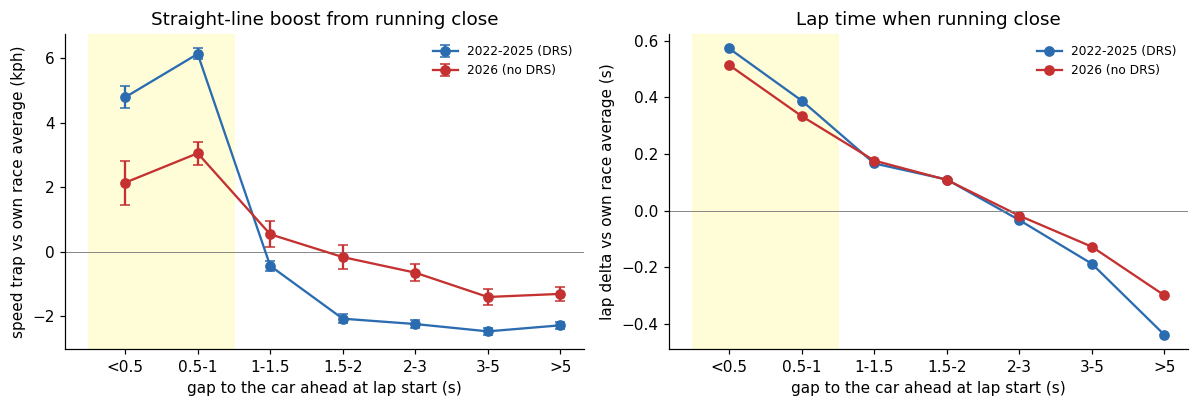

In [5]:
d = df.dropna(subset=['gap_ahead_s']).copy()
d['era'] = np.where(d.season < 2026, '2022-2025 (DRS)', '2026 (no DRS)')
key = ['season', 'event', 'driver']
for c in ['speed_trap_kph', 'lap_delta_s']:
    d[c + '_rel'] = d[c] - d.groupby(key)[c].transform('mean')
bins = [0, 0.5, 1, 1.5, 2, 3, 5, np.inf]
labels = ['<0.5', '0.5-1', '1-1.5', '1.5-2', '2-3', '3-5', '>5']
d['gap'] = pd.cut(d.gap_ahead_s, bins, labels=labels, right=False)
drs = d.groupby(['era', 'gap'], observed=True).agg(trap=('speed_trap_kph_rel', 'mean'), lap=('lap_delta_s_rel', 'mean'),
                                                     trap_se=('speed_trap_kph_rel', 'sem'), n=('lap', 'size')).reset_index()
boost = drs.pivot(index='gap', columns='era', values='trap')
gain = boost.loc[['<0.5', '0.5-1']].mean() - boost.loc['2-3']
print('Speed-trap boost within 1 s vs 2-3 s behind (kph):', gain.round(1).to_dict())

fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
for era, color in [('2022-2025 (DRS)', '#2b6cb0'), ('2026 (no DRS)', '#c53030')]:
    g = drs[drs.era == era]
    axs[0].errorbar(g.gap.astype(str), g.trap, yerr=1.96 * g.trap_se, marker='o', capsize=3, color=color, label=era)
    axs[1].plot(g.gap.astype(str), g.lap, marker='o', color=color, label=era)
axs[0].axvspan(-0.5, 1.5, color='#fefcbf', alpha=.6); axs[1].axvspan(-0.5, 1.5, color='#fefcbf', alpha=.6)
axs[0].set_ylabel('speed trap vs own race average (kph)'); axs[1].set_ylabel('lap delta vs own race average (s)')
for ax in axs:
    ax.set_xlabel('gap to the car ahead at lap start (s)'); ax.axhline(0, color='grey', lw=.6); ax.legend(frameon=False, fontsize=8)
axs[0].set_title('Straight-line boost from running close'); axs[1].set_title('Lap time when running close')
plt.tight_layout(); plt.savefig('figures/16_drs_removal.png', dpi=150); plt.show()

**Figure 16.** Removing DRS **more than halved** the straight-line boost of running close behind: inside 1 s, a car's speed-trap reading rose about 7.7 kph relative to running 2-3 s back in 2022-2025, and only about 3.3 kph in 2026. What's left is the slipstream plus the new overtake mode. The lap-time panel shows the other side of following: laps run close behind are *slower* than a driver's average in both eras, because dirty air and traffic cost more over a lap than DRS gained on one straight. That penalty is slightly smaller in 2026, which is what the active-aero, lower-downforce cars were designed to do, but the difference is small. One caveat: being stuck behind someone and being fast enough to catch them both put you in the <1 s bin, so these are associations, not causal effects of DRS alone.

### 4. Saturday vs Sunday: how far is race pace from qualifying pace?
For each driver at each race, we compare their median clean race lap with their best qualifying lap. A qualifying lap is run with minimum fuel, fresh soft tyres and everything deployed, so race laps are always slower; the question is whether the size of that gap changed. We drop the 13 weekends with a wet qualifying session (more than 5% of laps on intermediate or wet tyres), where the "best" qualifying lap is slower than the race and the comparison means nothing.

Dropped 13 wet-qualifying weekends
Median race-vs-qualifying gap by season (%): {2022: 7.35, 2023: 7.12, 2024: 7.43, 2025: 7.6, 2026: 6.05}
Circuits in both 2025 and 2026: 14 | gap smaller in 2026 at 11 of them


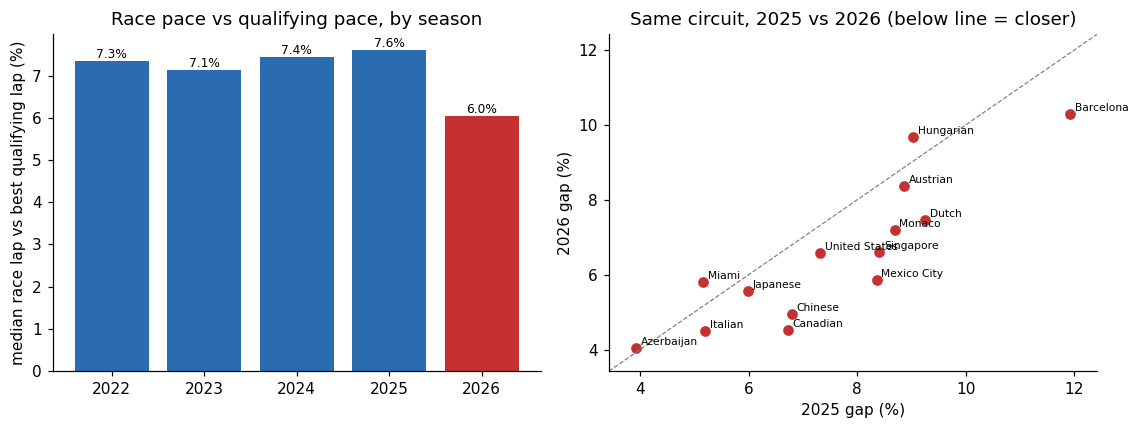

In [6]:
ql = load_quali(SEASONS)
wet_q = ql.groupby(['season', 'event']).compound.apply(lambda c: c.isin(['INTERMEDIATE', 'WET']).mean() > 0.05)
wet_q = set(wet_q[wet_q].index)
qb = quali_features(ql)[['season', 'event', 'driver', 'q_best']]
qr = df.groupby(['season', 'event', 'circuit', 'driver']).lap_time_s.median().reset_index().merge(qb, on=['season', 'event', 'driver'])
qr = qr[[(s, e) not in wet_q for s, e in zip(qr.season, qr.event)]]
qr['gap_pct'] = (qr.lap_time_s / qr.q_best - 1) * 100
print(f'Dropped {len(wet_q)} wet-qualifying weekends')
by_season = qr.groupby('season').gap_pct.median().round(2)
print('Median race-vs-qualifying gap by season (%):', by_season.to_dict())
circ = qr.groupby(['circuit', 'season']).gap_pct.median().unstack('season')
both = circ[[2025, 2026]].dropna()
print(f'Circuits in both 2025 and 2026: {len(both)} | gap smaller in 2026 at {(both[2026] < both[2025]).sum()} of them')

fig, axs = plt.subplots(1, 2, figsize=(10.5, 4))
axs[0].bar(by_season.index.astype(str), by_season.values, color=['#2b6cb0'] * 4 + ['#c53030'])
for x, v in zip(range(5), by_season.values): axs[0].text(x, v, f'{v:.1f}%', ha='center', va='bottom', fontsize=8)
axs[0].set_ylabel('median race lap vs best qualifying lap (%)'); axs[0].set_title('Race pace vs qualifying pace, by season')
axs[1].scatter(both[2025], both[2026], color='#c53030')
for name, r in both.iterrows(): axs[1].annotate(name, (r[2025], r[2026]), fontsize=7, xytext=(3, 2), textcoords='offset points')
lo, hi = both.values.min() - .5, both.values.max() + .5
axs[1].plot([lo, hi], [lo, hi], color='grey', lw=.8, ls='--'); axs[1].set_xlim(lo, hi); axs[1].set_ylim(lo, hi)
axs[1].set_xlabel('2025 gap (%)'); axs[1].set_ylabel('2026 gap (%)'); axs[1].set_title('Same circuit, 2025 vs 2026 (below line = closer)')
plt.tight_layout(); plt.savefig('figures/17_quali_to_race_gap.png', dpi=150); plt.show()

**Figure 17.** The opposite of what we expected. Our guess was that 2026 energy management would make race laps relatively slower than qualifying laps, but race pace actually sits **closer** to qualifying pace in 2026 (a median gap of 6.0% vs 7.1-7.6% in every earlier season), and it's closer at 11 of the 14 circuits raced in both 2025 and 2026. We can't separate the explanations with lap-timing data alone, but there are a few candidates: the 2026 power units may not be able to deploy everything for a full qualifying lap, which would shrink Saturday's advantage; race fuel loads and the fuel effect may be smaller (section 5 finds a ~17% smaller fuel effect per lap); and section 5 also finds softer tyres degrade far less in 2026, so race stints lose less time. Whatever the mix, it means that in 2026 Saturday pace converts more directly into Sunday pace, which is another reason qualifying features carry so much information this season.

### 5. Separating fuel burn from tyre wear
Within a stint, fuel load and tyre age both change by one lap per lap, so a stint-pace curve (like notebook 02's) can't tell them apart. But a pit stop resets tyre age while the fuel keeps burning, so *across* stints of the same driver in the same race, they come apart. We fit a linear model of the lap delta on laps of fuel on board, tyre age per compound and a compound offset, with a **fixed effect for each driver in each race** (all variables demeaned within driver-race), separately for 2022-2025 and 2026. 95% confidence intervals come from a **cluster bootstrap** that resamples whole races, because laps within a race aren't independent.

In [7]:
COEFS = ['fuel_proxy', 'age_SOFT', 'age_MEDIUM', 'age_HARD', 'cmp_MEDIUM', 'cmp_HARD']
def fe_ols(d, key_cols=('season', 'event', 'driver')):
    X = pd.DataFrame({'fuel_proxy': d.fuel_proxy.astype(float)})
    for c in ['SOFT', 'MEDIUM', 'HARD']:
        X[f'age_{c}'] = d.tyre_age.where(d.compound == c, 0.0)
    for c in ['MEDIUM', 'HARD']:
        X[f'cmp_{c}'] = (d.compound == c).astype(float)
    key = [d[k] for k in key_cols]
    Xd = X - X.groupby(key).transform('mean')
    yd = d.lap_delta_s - d.lap_delta_s.groupby(key).transform('mean')
    return pd.Series(np.linalg.lstsq(Xd.values, yd.values, rcond=None)[0], index=COEFS)

rng = np.random.RandomState(SEED)
est = {}
for era, m in {'2022-2025': df.season < 2026, '2026': df.season == 2026}.items():
    d = df[m]
    by_race = {k: g for k, g in d.groupby(['season', 'event'])}
    keys = list(by_race)
    boots = []
    for _ in range(200):
        pick = rng.randint(len(keys), size=len(keys))
        boots.append(fe_ols(pd.concat([by_race[keys[i]].assign(event=f'{keys[i][1]}#{j}') for j, i in enumerate(pick)])))
    B = pd.DataFrame(boots)
    est[era] = pd.DataFrame({'estimate': fe_ols(d), 'ci_low': B.quantile(.025), 'ci_high': B.quantile(.975)})
coef = pd.concat(est, axis=1)
coef.round(4)

2022-2025                     2026                
            estimate  ci_low ci_high estimate  ci_low ci_high
fuel_proxy    0.0507  0.0477  0.0551   0.0423  0.0363  0.0481
age_SOFT      0.0619  0.0515  0.0728   0.0288  0.0094  0.0483
age_MEDIUM    0.0412  0.0322  0.0507   0.0289  0.0147  0.0431
age_HARD      0.0313  0.0225  0.0400   0.0269  0.0098  0.0540
cmp_MEDIUM    0.3378  0.1922  0.4942   0.0443 -0.2015  0.2492
cmp_HARD      0.4137  0.2381  0.6087  -0.0168 -0.3572  0.2172

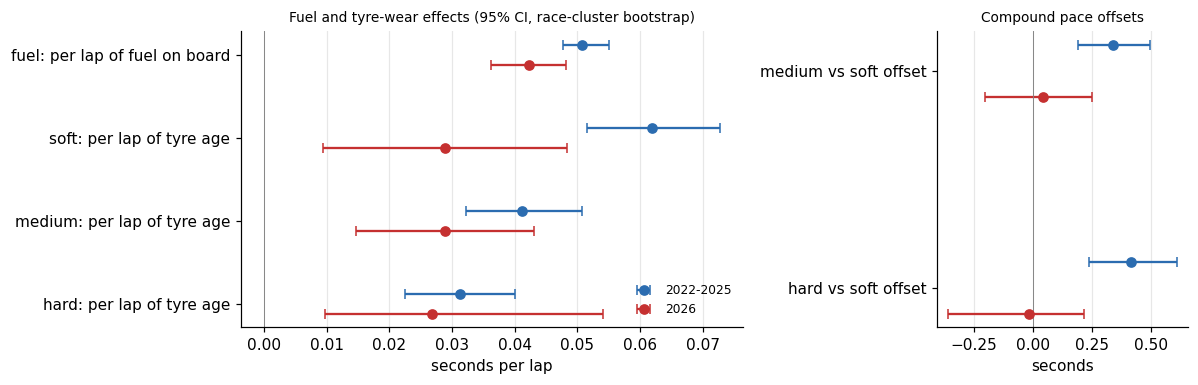

In [8]:
nice = {'fuel_proxy': 'fuel: per lap of fuel on board', 'age_SOFT': 'soft: per lap of tyre age',
        'age_MEDIUM': 'medium: per lap of tyre age', 'age_HARD': 'hard: per lap of tyre age',
        'cmp_MEDIUM': 'medium vs soft offset', 'cmp_HARD': 'hard vs soft offset'}
fig, axs = plt.subplots(1, 2, figsize=(11, 3.6), gridspec_kw={'width_ratios': [4, 2]})
for ax, names in [(axs[0], COEFS[:4]), (axs[1], COEFS[4:])]:
    yy = np.arange(len(names))[::-1]
    for off, (era, color) in zip([0.12, -0.12], [('2022-2025', '#2b6cb0'), ('2026', '#c53030')]):
        e = coef[era].loc[names]
        ax.errorbar(e.estimate, yy + off, xerr=[e.estimate - e.ci_low, e.ci_high - e.estimate], fmt='o', capsize=3,
                    color=color, label=era)
    ax.set_yticks(yy); ax.set_yticklabels([nice[n] for n in names]); ax.axvline(0, color='grey', lw=.6); ax.grid(axis='x', alpha=.3)
axs[0].set_xlabel('seconds per lap'); axs[1].set_xlabel('seconds'); axs[0].legend(frameon=False, fontsize=8)
axs[0].set_title('Fuel and tyre-wear effects (95% CI, race-cluster bootstrap)', fontsize=9); axs[1].set_title('Compound pace offsets', fontsize=9)
plt.tight_layout(); plt.savefig('figures/18_fuel_vs_tyre.png', dpi=150); plt.show()

**Figure 18.** This is the physical answer to notebook 05's "the race dynamics changed":
- **Soft tyres degrade about half as fast in 2026** (~0.03 s per lap vs ~0.06 s), and the confidence intervals don't overlap. Mediums and hards also wear a little more slowly, though their intervals overlap.
- **The pace gap between compounds has essentially disappeared.** In 2022-2025 a medium was ~0.3 s and a hard ~0.4 s slower than a soft on the same lap; in 2026 both offsets are indistinguishable from zero. Lighter, lower-downforce cars on Pirelli's narrower 2026 tyres seem to stress the rubber far less, so the softer compound's grip advantage barely shows over a race stint.
- **The fuel effect is ~17% smaller** (0.042 vs 0.051 s per lap of fuel), but the intervals just overlap, so this one is suggestive rather than conclusive.

This also explains why the stint-pace curves in notebook 02 looked so different: in 2026 tyre wear contributes much less, so the fuel burn-off dominates the shape of a stint. It's also why `tyre_age` lost importance in the SHAP comparison above. One caveat from our proposal still applies: tyre age isn't random (teams choose stint lengths strategically), so these are well-controlled associations, not clean causal effects.

### 6. Summary: what physically changed in 2026
1. **The pecking order reshuffled and spread out** (notebooks 03 and 05): the field went from ~3% to ~6% off pole, and team names from 2022-2025 stopped describing the cars. Qualifying pace fixes most of that.
2. **The cars lost time mainly in corners, not on straights** (section 2), consistent with reduced downforce, with energy-clipping signs only at the fastest tracks.
3. **Running close behind is worth less than half as much on the straights** without DRS (section 3).
4. **Tyres stopped mattering as much**: softs wear half as fast and the compound offsets vanished (section 5), so the lap-to-lap evolution our model learned from 2022-2025 no longer applies.
5. **Saturday converts more directly into Sunday** (section 4), which is part of why qualifying features are so informative in 2026.

Points 2-4 are the "within-race" part of the regime shift that no amount of retraining on a few 2026 races fixed in notebook 06: they're changes in the *relationships* between features and lap time, not just in which car is fast.